# Predicting Severe Building Damage from the 2015 Nepal Earthquake in Gorkha District Using Logistic Regression

1. Import Library

- pandas, numpy: Olah data dan operasi numerik
- matplotlib: Membuat grafik
- LogisticRegression: Model klasifikasi biner
- accuracy/precision/recall_score, confusion_matrix, roc_curve, roc_auc_score: Metrik evaluasi model
- train_test_split: Membagi data latih dan uji
- OneHotEncoder (category_encoders): Mengubah fitur kategorikal menjadi angka
- pd.set_option(...): Menampilkan semua kolom DataFrame

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from category_encoders import OneHotEncoder

# Set display options
pd.set_option('display.max_columns', None)

2. Memuat Data

- from duckdb_wrangle import wrangle_nepal_data → memakai fungsi buatan sendiri dari proyek sebelumnya.
- wrangle_nepal_data('./data', district_id=4) → memuat data Gorkha.
- Hasil: 70.836 baris × 7 kolom, tingkat kerusakan parah 64,26%.

In [2]:
from duckdb_wrangle import wrangle_nepal_data

# Load Gorkha district data (district_id = 4)
df = wrangle_nepal_data('./data', district_id=4)

print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(f"\nSevere damage rate: {df['severe_damage'].mean():.2%}")
print(f"\nFirst few rows:")
print(df.head())

Dataset shape: (70836, 7)
Columns: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type', 'severe_damage']

Severe damage rate: 64.26%

First few rows:
             district_id  age_building  plinth_area_sq_ft  height_ft_pre_eq  \
building_id                                                                   
165334                 4            15                240                14   
165438                 4            17                250                12   
165441                 4            12                180                12   
165900                 4            15                441                19   
164209                 4            25                250                13   

                    foundation_type ground_floor_type  severe_damage  
building_id                                                           
165334       Mud mortar-Stone/Brick       Brick/Stone              1  
165438       Mud mortar

3. Distribusi Kelas Target

- value_counts(normalize=True) → menghitung proporsi kelas.
- plot(kind='bar') → diagram batang.
- Hasil: 64,26% parah (1) vs 35,74% tidak parah (0).

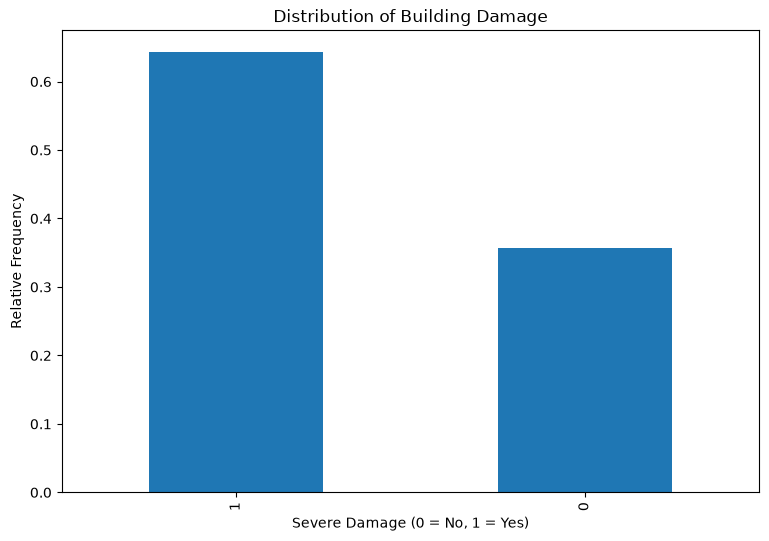

Class distribution:
severe_damage
1    0.642597
0    0.357403
Name: proportion, dtype: float64


In [3]:
# Calculate class distribution
class_distribution = df['severe_damage'].value_counts(normalize=True)

# Create bar plot
fig, ax = plt.subplots(figsize=(9, 6))
class_distribution.plot(kind='bar', ax=ax)
ax.set_xlabel("Severe Damage (0 = No, 1 = Yes)")
ax.set_ylabel("Relative Frequency")
ax.set_title("Distribution of Building Damage")
plt.show()

print(f"Class distribution:\n{class_distribution}")

4. Cek Fitur Kategorikal

- select_dtypes('object').nunique() → menghitung jumlah nilai unik fitur bertipe teks.
- Hasil: foundation_type dan ground_floor_type masing-masing 5 kategori.

In [4]:
# Get categorical columns and their unique value counts
cat_unique_counts = df.select_dtypes('object').nunique()   # <--- 'object'

print("Categorical feature unique value counts:")
print(cat_unique_counts)

Categorical feature unique value counts:
foundation_type      5
ground_floor_type    5
dtype: int64


C:\Users\jason\AppData\Local\Temp\ipykernel_6912\2684031601.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_unique_counts = df.select_dtypes('object').nunique()   # <--- 'object'


5. Heatmap Korelasi

- .corr() pada fitur numerik (tanpa target) lalu sns.heatmap.
- Hasil: korelasi antarfitur rendah. Tertinggi plinth_area vs height (0,28). district_id bernilai NaN karena nilainya konstan (selalu 4).

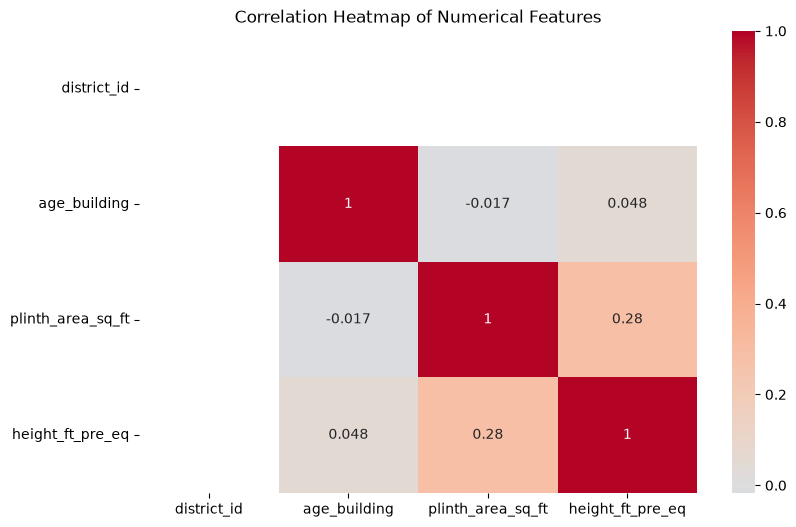

Correlation matrix created!
                   district_id  age_building  plinth_area_sq_ft  \
district_id                NaN           NaN                NaN   
age_building               NaN      1.000000          -0.016856   
plinth_area_sq_ft          NaN     -0.016856           1.000000   
height_ft_pre_eq           NaN      0.047652           0.283496   

                   height_ft_pre_eq  
district_id                     NaN  
age_building               0.047652  
plinth_area_sq_ft          0.283496  
height_ft_pre_eq           1.000000  


In [5]:
import seaborn as sns

# Create correlation matrix for numerical features
correlation = df.select_dtypes('number').drop(columns='severe_damage').corr()

# Plot heatmap
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap of Numerical Features')
plt.show()

print("Correlation matrix created!")
print(correlation)

6. Boxplot Tinggi Bangunan

- sns.boxplot(x='severe_damage', y='height_ft_pre_eq') → membandingkan tinggi bangunan berdasarkan tingkat kerusakan.

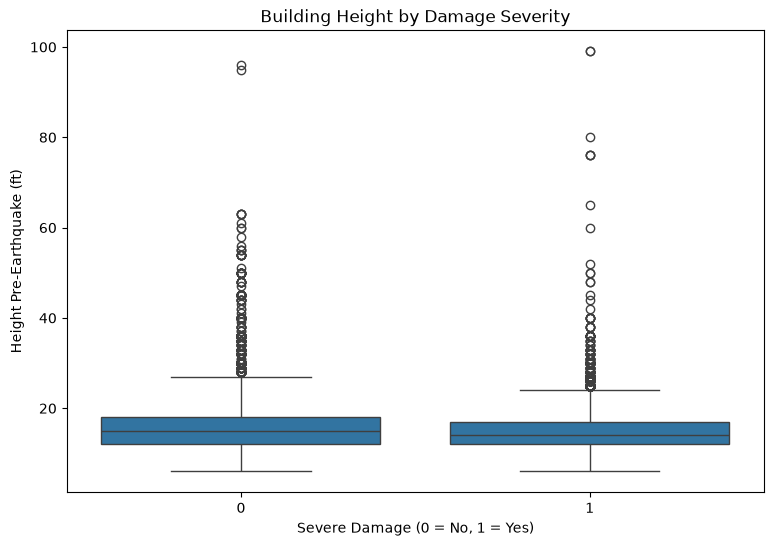

Boxplot created!


In [6]:
# Create boxplot
fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(x='severe_damage', y='height_ft_pre_eq', data=df, ax=ax)
ax.set_xlabel('Severe Damage (0 = No, 1 = Yes)')
ax.set_ylabel('Height Pre-Earthquake (ft)')
ax.set_title('Building Height by Damage Severity')
plt.show()

print("Boxplot created!")

7. Tingkat Kerusakan per Jenis Pondasi

- pd.pivot_table(..., aggfunc='mean') → rata-rata kerusakan parah per pondasi.
- Garis merah putus-putus = rata-rata keseluruhan.
- Hasil: RC 2,6% (paling aman) → Bamboo/Timber 32% → Cement-Stone/Brick 42% → Mud mortar-Stone/Brick 69% → Other 82% (paling rentan).

Severe damage rate by foundation type:
                        severe_damage
foundation_type                      
RC                           0.026224
Bamboo/Timber                0.324074
Cement-Stone/Brick           0.421908
Mud mortar-Stone/Brick       0.687792
Other                        0.818898


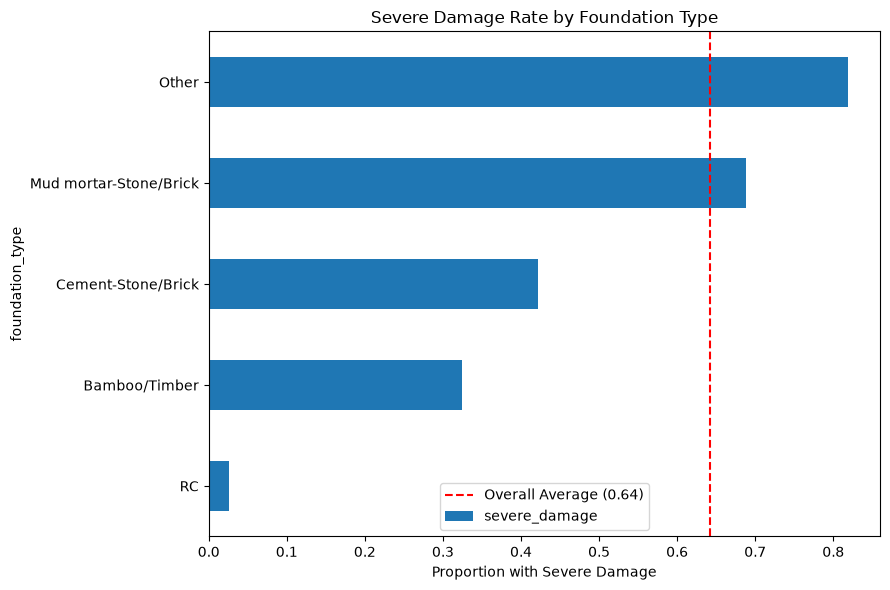

In [7]:
# Create pivot table
foundation_damage = pd.pivot_table(
    df, values='severe_damage',
    index='foundation_type',
    aggfunc='mean'
).sort_values('severe_damage')

print("Severe damage rate by foundation type:")
print(foundation_damage)

# Plot horizontal bar chart
fig, ax = plt.subplots(figsize=(9, 6))
foundation_damage.plot(kind='barh', ax=ax, legend=False)
ax.set_xlabel('Proportion with Severe Damage')
ax.set_title('Severe Damage Rate by Foundation Type')
ax.axvline(x=df['severe_damage'].mean(), color='red', linestyle='--',
           label=f'Overall Average ({df["severe_damage"].mean():.2f})')
ax.legend()
plt.tight_layout()
plt.show()

8. Menentukan Target dan Fitur

- target = 'severe_damage'; fitur dipilih dengan list comprehension (semua kolom selain target) → 6 fitur.

In [8]:
# Define target variable
target = 'severe_damage'

# Get all columns except target using list comprehension
features = [col for col in df.columns if col != target]

print(f"Target: {target}")
print(f"Number of features: {len(features)}")
print(f"Features: {features}")

Target: severe_damage
Number of features: 6
Features: ['district_id', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'foundation_type', 'ground_floor_type']


8. Membentuk X dan y

- X = df[features] (fitur), y = df[target] (label).
- Shape: X (70836, 6), y (70836,).

In [9]:
# Create feature matrix and target vector
X = df[features]
y = df[target]

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"\nFirst 5 rows of X:")
print(X.head())
print(f"\nFirst 5 values of y:")
print(y.head())

X shape: (70836, 6)
y shape: (70836,)

First 5 rows of X:
             district_id  age_building  plinth_area_sq_ft  height_ft_pre_eq  \
building_id                                                                   
165334                 4            15                240                14   
165438                 4            17                250                12   
165441                 4            12                180                12   
165900                 4            15                441                19   
164209                 4            25                250                13   

                    foundation_type ground_floor_type  
building_id                                            
165334       Mud mortar-Stone/Brick       Brick/Stone  
165438       Mud mortar-Stone/Brick       Brick/Stone  
165441       Mud mortar-Stone/Brick       Brick/Stone  
165900       Mud mortar-Stone/Brick       Brick/Stone  
164209       Mud mortar-Stone/Brick               Mu

10. Pembagian Data

- train_test_split(test_size=0.2, random_state=42)
- Latih: 56.668 baris | Uji: 14.168 baris.

In [10]:
# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Test set: X_test {X_test.shape}, y_test {y_test.shape}")

Training set: X_train (56668, 6), y_train (56668,)
Test set: X_test (14168, 6), y_test (14168,)


11. Akurasi Baseline

- Menghitung akurasi jika selalu menebak kelas mayoritas (.max()).
- Hasil: 64,40%, menjadi patokan minimum yang harus dikalahkan model.

In [11]:
# Calculate baseline accuracy (predict majority class)
baseline_acc = y_train.value_counts(normalize=True).max()  # <--- max()

print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"This means predicting '{y_train.value_counts().idxmax()}' for all buildings gives {baseline_acc:.2%} accuracy")

Baseline Accuracy: 0.6418
This means predicting '1' for all buildings gives 64.18% accuracy


12. Melatih Model

- Pipeline berisi: OneHotEncoder → LogisticRegression(max_iter=1000).
- model.fit(X_train, y_train).
Catatan: muncul ConvergenceWarning, artinya model belum konvergen penuh (fitur numerik belum diskalakan).

In [12]:
from sklearn.pipeline import Pipeline

# Create pipeline with OneHotEncoder and LogisticRegression
model = Pipeline([
    ('encoder', OneHotEncoder(use_cat_names=True)),
    ('classifier', LogisticRegression(max_iter=2000))
])

# Fit the model
model.fit(X_train, y_train)

print("Model trained successfully!")
print(f"\nModel steps: {model.steps}")

Model trained successfully!

Model steps: [('encoder', OneHotEncoder(cols=['foundation_type', 'ground_floor_type'], use_cat_names=True)), ('classifier', LogisticRegression(max_iter=2000))]


13. Akurasi Model

- Latih 70,54%, Uji 70,14%, baseline 64,40%.
- Peningkatan 5,73 poin persentase. Selisih latih-uji kecil, jadi tidak overfitting.

In [13]:
# Calculate accuracy scores
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Baseline Accuracy: {baseline_acc:.4f}")
print(f"\nImprovement over baseline: {test_acc - baseline_acc:.4f}")

Training Accuracy: 0.7037
Test Accuracy: 0.7077
Baseline Accuracy: 0.6418

Improvement over baseline: 0.0658


14. Precision dan Recall

- Precision 69,06%: saat model memprediksi “parah”, benar 69% kali.
- Recall 96,20%: model menangkap 96% bangunan yang benar-benar rusak parah.

In [14]:
# Calculate precision and recall
y_pred = model.predict(X_test)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print("\nInterpretation:")
print(f"- Precision: When model predicts severe damage, it is correct {precision:.2%} of the time")
print(f"- Recall: Model identifies {recall:.2%} of all severely damaged buildings")

Precision: 0.6975
Recall: 0.9663

Interpretation:
- Precision: When model predicts severe damage, it is correct 69.75% of the time
- Recall: Model identifies 96.63% of all severely damaged buildings


15. Confusion Matrix

- Aktual Tidak Parah: 
    - Prediksi Tidak Parah = 1.257	
    - Prediksi Parah = 3.888 (false positive)
- Aktual Parah	
    - Prediksi Tidak Parah = 343 (false negative)	
    - Prediksi Parah = 8.680
Model sangat condong memprediksi “parah”, sehingga banyak bangunan aman salah dilabeli parah.

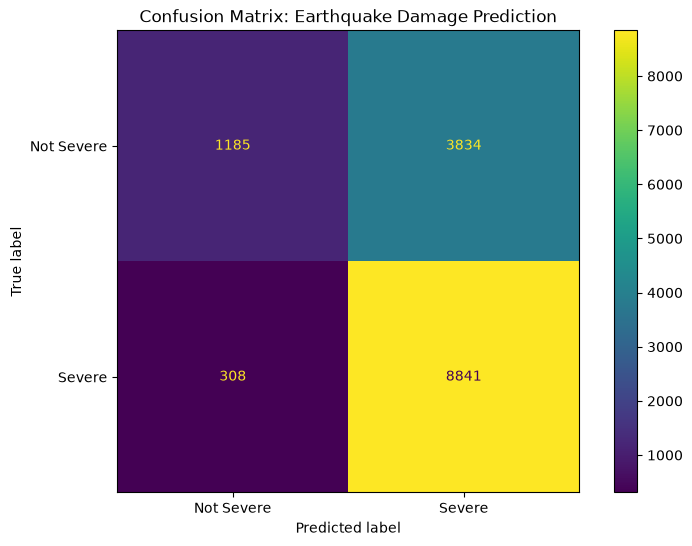

Confusion Matrix:
[[1185 3834]
 [ 308 8841]]


In [15]:
# Create confusion matrix
cm = confusion_matrix(y_test, model.predict(X_test))

# Display confusion matrix
fig, ax = plt.subplots(figsize=(9, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Severe', 'Severe'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix: Earthquake Damage Prediction')
plt.show()

print("Confusion Matrix:")
print(cm)

16. Kurva ROC & AUC

- roc_curve dan roc_auc_score dari probabilitas prediksi.
- AUC = 0,633 (0,5 = tebakan acak, 1,0 = sempurna), tergolong lemah.

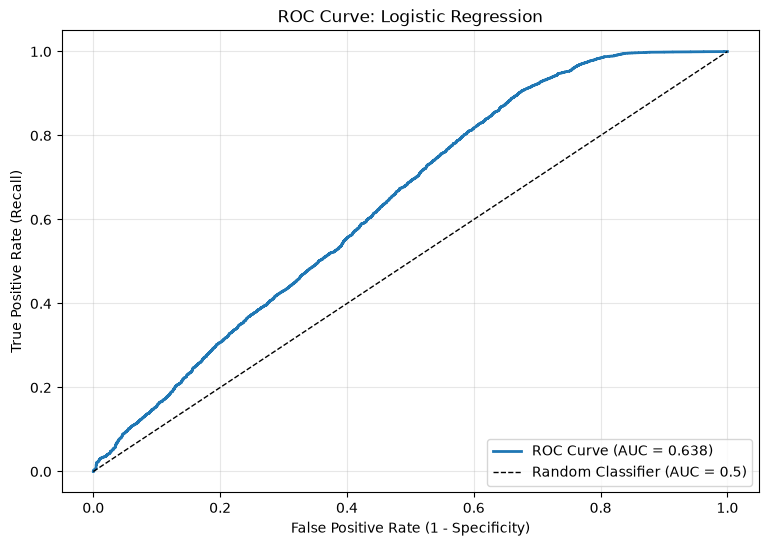

AUC Score: 0.6384

Interpretation:
- AUC = 0.5: Random guessing
- AUC = 1.0: Perfect classifier
- AUC = 0.638: Our model's performance


In [16]:
# Get predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.5)', linewidth=1)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curve: Logistic Regression')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.show()

print(f"AUC Score: {auc_score:.4f}")
print(f"\nInterpretation:")
print(f"- AUC = 0.5: Random guessing")
print(f"- AUC = 1.0: Perfect classifier")
print(f"- AUC = {auc_score:.3f}: Our model's performance")

17. Odds Ratio

- np.exp(coef_) → mengubah koefisien menjadi odds ratio.
- Menurunkan risiko kerusakan parah: pondasi RC (0,08), lantai dasar RC (0,34), pondasi Bamboo/Timber (0,65).
- Menaikkan risiko: pondasi Other (4,77x), Mud mortar-Stone/Brick (2,83x), lantai Timber (2,0x).

In [17]:
# Extract feature names and coefficients
feature_names = model.named_steps['encoder'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]

# Calculate odds ratios
odds_ratios = pd.Series(np.exp(coefficients), index=feature_names).sort_values()

print("Top 5 features that DECREASE odds of severe damage:")
print(odds_ratios.head())
print("\nTop 5 features that INCREASE odds of severe damage:")
print(odds_ratios.tail())

Top 5 features that DECREASE odds of severe damage:
foundation_type_RC               0.088049
ground_floor_type_RC             0.343770
foundation_type_Bamboo/Timber    0.647816
ground_floor_type_Other          0.806002
district_id                      0.855176
dtype: float64

Top 5 features that INCREASE odds of severe damage:
foundation_type_Cement-Stone/Brick        1.303659
ground_floor_type_Brick/Stone             1.521189
ground_floor_type_Timber                  1.939501
foundation_type_Mud mortar-Stone/Brick    2.852630
foundation_type_Other                     4.533427
dtype: float64


In [18]:
feature_names

array(['district_id', 'age_building', 'plinth_area_sq_ft',
       'height_ft_pre_eq', 'foundation_type_Cement-Stone/Brick',
       'foundation_type_Bamboo/Timber',
       'foundation_type_Mud mortar-Stone/Brick', 'foundation_type_RC',
       'foundation_type_Other', 'ground_floor_type_RC',
       'ground_floor_type_Timber', 'ground_floor_type_Mud',
       'ground_floor_type_Brick/Stone', 'ground_floor_type_Other'],
      dtype=object)

18. Visualisasi Top 10 Odds Ratio

- Diagram batang horizontal dengan garis merah di OR = 1 (tanpa efek).

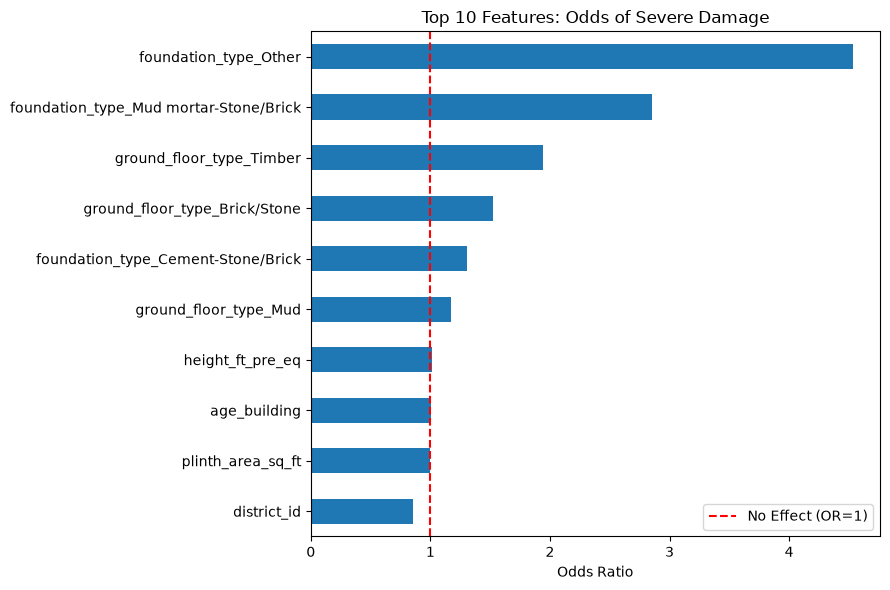

In [19]:
# Plot top 10 odds ratios
fig, ax = plt.subplots(figsize=(9, 6))
odds_ratios.tail(10).plot(kind='barh', ax=ax)
ax.set_xlabel('Odds Ratio')
ax.set_title('Top 10 Features: Odds of Severe Damage')
ax.axvline(x=1, color='red', linestyle='--', label='No Effect (OR=1)')
ax.legend()
plt.tight_layout()
plt.show()

Kesimpulan Singkat

- Tujuan: memprediksi apakah bangunan di Gorkha mengalami kerusakan parah (Grade 4-5) berdasarkan 6 fitur struktur bangunan.
- Performa model: akurasi uji 70,14%, hanya sedikit di atas baseline 64,40%. AUC 0,633 menunjukkan kemampuan membedakan kelas masih terbatas.
- Karakter model: recall tinggi (96%) tetapi precision sedang (69%). Model cenderung “waspada berlebihan”, cocok bila prioritasnya tidak melewatkan bangunan berbahaya, namun banyak alarm palsu.
- Temuan utama: jenis pondasi dan lantai dasar adalah faktor paling berpengaruh. Pondasi beton bertulang (RC) sangat protektif, sedangkan pondasi “Other” dan batu dengan mortar lumpur sangat meningkatkan risiko.

Saran perbaikan:
- Hapus district_id (konstan, tidak informatif).
- Skalakan fitur numerik (StandardScaler) agar model konvergen.
- Tambah fitur (jumlah lantai, jenis atap, kondisi lahan, dll.) dan coba model non-linear seperti Random Forest atau Gradient Boosting.
- Atur threshold klasifikasi untuk menyeimbangkan precision dan recall.